In [73]:
import torch
import numpy as np
import matplotlib.pyplot as plt

torch.Size([3, 5, 100, 100])
tensor([0.9995, 0.9993, 0.9992])


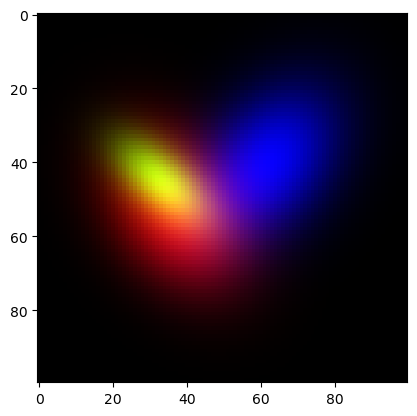

In [243]:
def generate_covar(s1: torch.Tensor, s2: torch.Tensor, alpha: torch.Tensor):
    """
    creates valid covariance matrices from 2 eigenvalues (positive!) and one orientation (0-2pi)

    Args:
        s1    (torch.Tensor): first singular value  [BS, nBlobs]
        s2    (torch.Tensor): second singular value [BS, nBlobs]
        alpha (torch.Tensor): angle in rad          [BS, nBlobs]
        
    Returns:
        covar (torch.Tensor): [BS, nBlobs, 2, 2]
    """
    
    # create the diagonal matrix from the singular values => [BS, nBlobs, 2, 2]    
    sigma = torch.concat([s1[:, :, None], s2[:, :, None]], dim=2)
    sigma = torch.diag_embed(sigma)
    
    # create the rotation matrices from angle alpha => [BS, nBlobs, 2, 2]
    sin_alpha = torch.sin(alpha)
    cos_alpha = torch.cos(alpha)
    rotmat    = torch.concat([
        torch.concat([cos_alpha[:, :, None], -sin_alpha[:, :, None]], dim=2)[:, :, :, None],
        torch.concat([sin_alpha[:, :, None],  cos_alpha[:, :, None]], dim=2)[:, :, :, None],
    ], dim=3)
    
    # produce covariance mat by: covar = R.T @ Σ @ R (broadcasting over BS and nBlobs)
    covar = torch.einsum("BNji, BNjk, BNkl -> BNil", rotmat, sigma, rotmat)
    return covar

def batched_2D_gaussian(covar: torch.Tensor, mean: torch.Tensor, strength: torch.Tensor, POS: torch.Tensor):
    """
    returns the 2D gaussian (=Z) at position (X, Y) over the whole 2D grid. 
    Uses the formula 1/(2pi * |Σ|**0.5) * exp[-0.5 * (x-μ).T @ Σ^(-1) @ (x-μ)]

    Args:
        covar    (torch.Tensor): [BS, nBlobs, 2, 2]
        mean     (torch.Tensor): [BS, nBlobs, 2]
        strength (torch.Tensor): [BS, nBlobs] 
        POS      (torch.Tensor): [szX, szY, 2]
    """
    
    # get current variable dimensions for reshaping
    BS     = covar.shape[0]
    nBlobs = covar.shape[1]
    
    # subtract mean to get deviations => [BS, nBlobs, szX, szY, 2]
    dev = POS[None, None, :, :, :] - mean[:, :, None, None, :]
    
    # regularize (for stability) and invert covariances => [BS, nBlobs, 2, 2]
    epsilon   = 10**-5
    covar_inv = covar + epsilon * torch.eye(2)[None, None, :, :]
    covar_inv = torch.inverse(covar_inv)
    
    # calculate det(covariances) => [BS, nBlobs]
    covar_det = torch.det(covar)
    
    # calculate the exponent (= mahalanobis distance) with dev.T @ Σ.inv @ dev. Watch out, when broadcasting formula, doing dev.T @ Σ.inv @ dev is actually wrong, as for the second @, only the diagonal of the result would be needed! (many unsensible coordinate combinations are calculated in the off-diagonals this way)
    mahalanobi  = torch.einsum("BNxyi, BNij, BNxyj -> BNxy", dev, covar_inv, dev)
    
    # calculate the rest of the equation 
    norm_factor = 1 / (2*torch.pi * torch.sqrt(covar_det))
    pdfs        = torch.einsum("BN, BNxy -> BNxy", norm_factor, torch.exp(-0.5 * mahalanobi))
    
    pdfs = torch.exp(-0.5 * mahalanobi)
    return pdfs


### --------------------------------------------------------------------------------------------------------------------
BS     = 3
nBlobs = 5

covar_param = torch.rand(BS, nBlobs, 3)# [s1, s2, alpha]

# prepare all elements
covar    = generate_covar(s1=covar_param[:, :, 0], s2=covar_param[:, :, 1], alpha=2*torch.pi*covar_param[:, :, 2])
mean     = 2*torch.rand(BS, nBlobs, 2) - 1
strength = torch.rand(BS, nBlobs)

# prepare output grid (POS)  
grid_lim = [-3, 3]
grid_res = 100
x, y = torch.linspace(grid_lim[0], grid_lim[1], grid_res), torch.linspace(grid_lim[0], grid_lim[1], grid_res)
X, Y = torch.meshgrid(x, y, indexing="ij")
POS  = torch.concat([X[:, :, None], Y[:, :, None]], dim=2)

# get pdf over grid
pdfs = batched_2D_gaussian(covar, mean, strength, POS)
print(pdfs.shape)


# visualizes some pdfs 
aaa = pdfs.detach().cpu()[0, 0:3, :, :]
aaa = aaa.permute(1, 2, 0)
maxes = torch.amax(aaa, dim=(0, 1))
print(maxes)


plt.imshow(aaa)



